# DSA 312: Exploratory Data Analysis & Predictive Modeling
## Predicting Student Exam Risk (`below80`) from Attendance, Homework, Demographics, and Communications

### 1. Problem Identification & Analytical Objective
The objective of this notebook is to perform end-to-end exploratory data analysis (EDA), data quality remediation, multi-table feature engineering, and binary classification modeling to identify students at risk of scoring **below 80** on subject exams (`below80 = 1`).

**Datasets & Grain:**
- `students.csv`: Student-level demographics (`Student_ID` grain)
- `attendance.csv`: Daily/session attendance logs (`Student_ID`, `Subject`, `Date` grain)
- `homework.csv`: Assignment completion and status records (`Student_ID`, `Subject`, `Due_Date` / `Assignment` grain)
- `performance.csv`: Subject-level exam scores (`Student_ID`, `Subject` grain — modeling target grain)
- `teacher_parent_communication.csv`: Parent/guardian communication logs (`Student_ID` grain)

In [8]:
# Core Libraries
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Modeling & Evaluation
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, RocCurveDisplay, precision_recall_fscore_support
)

sns.set_theme(style='whitegrid', palette='muted')
pd.set_option('display.max_columns', 50)

### 2. Data Loading & Schema Overview

In [9]:
# Load datasets using exact workspace filenames
DATA_DIR = './'

students = pd.read_csv(f'{DATA_DIR}students.csv')
attendance = pd.read_csv(f'{DATA_DIR}attendance.csv')
homework = pd.read_csv(f'{DATA_DIR}homework.csv')
exams = pd.read_csv(f'{DATA_DIR}performance.csv')
communications = pd.read_csv(f'{DATA_DIR}teacher_parent_communication.csv')

datasets = {
    'students': students,
    'attendance': attendance,
    'homework': homework,
    'performance (exams)': exams,
    'teacher_parent_communication': communications
}

for name, df in datasets.items():
    print(f'=== {name.upper()} ({df.shape[0]:,} rows x {df.shape[1]} cols) ===')
    print('Columns:', list(df.columns))
    print('Missing values:\n', df.isnull().sum()[df.isnull().sum() > 0])
    print('Exact duplicate rows:', df.duplicated().sum())
    print('-' * 55)

=== STUDENTS (12,156 rows x 5 cols) ===
Columns: ['Student_ID', 'Full_Name', 'Date_of_Birth', 'Grade_Level', 'Emergency_Contact']
Missing values:
 Emergency_Contact    618
dtype: int64
Exact duplicate rows: 0
-------------------------------------------------------
=== ATTENDANCE (364,680 rows x 4 cols) ===
Columns: ['Student_ID', 'Date', 'Subject', 'Attendance_Status']
Missing values:
 Series([], dtype: int64)
Exact duplicate rows: 290
-------------------------------------------------------
=== HOMEWORK (60,780 rows x 7 cols) ===
Columns: ['Student_ID', 'Subject', 'Assignment_Name', 'Due_Date', 'Status', 'Grade_Feedback', 'Guardian_Signature']
Missing values:
 Series([], dtype: int64)
Exact duplicate rows: 0
-------------------------------------------------------
=== PERFORMANCE (EXAMS) (36,468 rows x 5 cols) ===
Columns: ['Student_ID', 'Subject', 'Exam_Score', 'Homework_Completion_%', 'Teacher_Comments']
Missing values:
 Series([], dtype: int64)
Exact duplicate rows: 0
---------------

### 3. Data Cleaning, Normalization & Anomaly Handling
Based on initial audit findings:
1. **Date Parsing:** Standardize date columns across `attendance`, `homework`, `performance`, and `communications`.
2. **Categorical Standardization:** Normalize casing/whitespace on `Attendance_Status` and `Homework Status` (or equivalent status columns).
3. **Duplicate Key Remediation:** Deduplicate repeated `(Student_ID, Subject, Date)` keys in `attendance.csv` (resolving the ~2,380 repeated composite keys).
4. **Out-of-Range & Anomaly Treatment:**
   - Flag and cap/clean invalid negative values (e.g., `-5` in `Homework_Completion_%`) to `[0, 100]`.
   - Inspect exam scores `> 100` (e.g., extra credit vs. entry error) and clip or document clearly before deriving `below80`.

In [10]:
# Helper to identify column names flexibly across minor naming variations
def find_col(df, candidates):
    lower_map = {c.lower().strip(): c for c in df.columns}
    for cand in candidates:
        if cand.lower() in lower_map:
            return lower_map[cand.lower()]
    for c in df.columns:
        for cand in candidates:
            if cand.lower() in c.lower():
                return c
    return None

# 1. Clean Attendance
att = attendance.copy()
att_date_col = find_col(att, ['Date', 'Attendance_Date'])
att_status_col = find_col(att, ['Attendance_Status', 'Status'])
if att_date_col:
    att[att_date_col] = pd.to_datetime(att[att_date_col], errors='coerce')
if att_status_col:
    att[att_status_col] = att[att_status_col].astype(str).str.strip().str.title()

att_key_cols = [c for c in ['Student_ID', 'Subject', att_date_col] if c and c in att.columns]
before_att = len(att)
att = att.drop_duplicates(subset=att_key_cols, keep='last')
print(f'Attendance deduplicated on {att_key_cols}: {before_att:,} -> {len(att):,} rows (removed {before_att - len(att):,})')

# 2. Clean Homework (strip '%' signs first so '80%' -> 80.0 instead of NaN!)
hw = homework.copy()
hw_comp_col = find_col(hw, ['Homework_Completion_%', 'Completion_%', 'Completion'])
hw_status_col = find_col(hw, ['Homework Status', 'Homework_Status', 'Status'])
hw_date_col = find_col(hw, ['Due_Date', 'Date', 'Submission_Date'])

if hw_date_col:
    hw[hw_date_col] = pd.to_datetime(hw[hw_date_col], errors='coerce')
if hw_status_col:
    hw[hw_status_col] = hw[hw_status_col].astype(str).str.strip().str.title()
if hw_comp_col:
    hw[hw_comp_col] = (
        hw[hw_comp_col].astype(str).str.replace('%', '', regex=False).str.strip()
    )
    hw[hw_comp_col] = pd.to_numeric(hw[hw_comp_col], errors='coerce')
    neg_count = (hw[hw_comp_col] < 0).sum()
    over_count = (hw[hw_comp_col] > 100).sum()
    print(f'Homework completion anomalies -> <0: {neg_count}, >100: {over_count} (clipping to [0, 100])')
    hw[hw_comp_col] = hw[hw_comp_col].clip(lower=0, upper=100)

hw = hw.drop_duplicates()

# 3. Clean Exams / Performance (`performance.csv`)
ex = exams.copy()
score_col = find_col(ex, ['Exam_Score', 'Score', 'Grade'])
ex_date_col = find_col(ex, ['Exam_Date', 'Date'])
if ex_date_col:
    ex[ex_date_col] = pd.to_datetime(ex[ex_date_col], errors='coerce')
ex[score_col] = pd.to_numeric(ex[score_col], errors='coerce')

# If performance.csv also contains a summary Homework_Completion_% column, clean & clip it too!
ex_hw_col = find_col(ex, ['Homework_Completion_%', 'Completion_%'])
if ex_hw_col:
    ex[ex_hw_col] = (
        ex[ex_hw_col].astype(str).str.replace('%', '', regex=False).str.strip()
    )
    ex[ex_hw_col] = pd.to_numeric(ex[ex_hw_col], errors='coerce').clip(lower=0, upper=100)
    ex = ex.rename(columns={ex_hw_col: 'perf_hw_completion_pct'})

print(f'Exam scores > 100 count: {(ex[score_col] > 100).sum()} | < 0 count: {(ex[score_col] < 0).sum()}')
ex = ex.dropna(subset=['Student_ID', 'Subject', score_col]).drop_duplicates(subset=['Student_ID', 'Subject'], keep='last')

# Binary target: 1 if exam score < 80, else 0
ex['below80'] = (ex[score_col] < 80).astype(int)
print('\nTarget Class Balance (`below80`):')
print(ex['below80'].value_counts(normalize=True).rename('proportion').round(4))

Attendance deduplicated on ['Student_ID', 'Subject', 'Date']: 364,680 -> 362,300 rows (removed 2,380)
Exam scores > 100 count: 5139 | < 0 count: 0

Target Class Balance (`below80`):
below80
1    0.563
0    0.437
Name: proportion, dtype: float64


### 4. Multi-Table Feature Engineering (Aggregating to `Student_ID` + `Subject` Grain)

In [11]:
# --- A. Attendance Features at (Student_ID, Subject) grain ---
att['is_present'] = att[att_status_col].str.contains('Present', case=False, na=False).astype(int)
att['is_absent'] = att[att_status_col].str.contains('Absent', case=False, na=False).astype(int)
att['is_late'] = att[att_status_col].str.contains('Late|Tardy', case=False, na=False).astype(int)
att['is_excused'] = att[att_status_col].str.contains('Excused', case=False, na=False).astype(int)

att_agg = att.groupby(['Student_ID', 'Subject'], as_index=False).agg(
    att_total_sessions=('is_present', 'count'),
    att_present_count=('is_present', 'sum'),
    att_absent_count=('is_absent', 'sum'),
    att_late_count=('is_late', 'sum'),
    att_excused_count=('is_excused', 'sum')
)
att_agg['attendance_rate'] = att_agg['att_present_count'] / att_agg['att_total_sessions']
att_agg['absence_rate'] = att_agg['att_absent_count'] / att_agg['att_total_sessions']
att_agg['tardy_rate'] = att_agg['att_late_count'] / att_agg['att_total_sessions']

# --- B. Homework Features at (Student_ID, Subject) grain ---
hw_agg_dict = {'Student_ID': ('Student_ID', 'count')}
if hw_comp_col:
    hw_agg = hw.groupby(['Student_ID', 'Subject'], as_index=False).agg(
        hw_count=(hw_comp_col, 'count'),
        hw_mean_completion=(hw_comp_col, 'mean'),
        hw_min_completion=(hw_comp_col, 'min'),
        hw_std_completion=(hw_comp_col, 'std')
    )
    hw_agg['hw_std_completion'] = hw_agg['hw_std_completion'].fillna(0)
else:
    hw_agg = hw.groupby(['Student_ID', 'Subject'], as_index=False).size().rename(columns={'size': 'hw_count'})

if hw_status_col:
    hw['hw_missing_flag'] = hw[hw_status_col].str.contains('Missing|Incomplete|Not', case=False, na=False).astype(int)
    hw['hw_late_flag'] = hw[hw_status_col].str.contains('Late', case=False, na=False).astype(int)
    hw_flags = hw.groupby(['Student_ID', 'Subject'], as_index=False).agg(
        hw_missing_rate=('hw_missing_flag', 'mean'),
        hw_late_rate=('hw_late_flag', 'mean')
    )
    hw_agg = hw_agg.merge(hw_flags, on=['Student_ID', 'Subject'], how='left')

# --- C. Communications Features at (Student_ID) grain ---
comm = communications.drop_duplicates().copy()
comm_agg = comm.groupby('Student_ID', as_index=False).size().rename(columns={'size': 'comm_total_count'})

# --- D. Merge All Tables onto Exams Grain ---
df_model = (
    ex.merge(students.drop_duplicates(subset=['Student_ID']), on='Student_ID', how='left')
      .merge(att_agg, on=['Student_ID', 'Subject'], how='left')
      .merge(hw_agg, on=['Student_ID', 'Subject'], how='left')
      .merge(comm_agg, on='Student_ID', how='left')
)

# Students with 0 records in communications have 0 communications
df_model['comm_total_count'] = df_model['comm_total_count'].fillna(0)

print(f'Final analytical dataset shape: {df_model.shape[0]:,} rows x {df_model.shape[1]} columns')
df_model.head()

Final analytical dataset shape: 28,736 rows x 22 columns


,Student_ID,Subject,Exam_Score,perf_hw_completion_pct,Teacher_Comments,below80,Full_Name,Date_of_Birth,Grade_Level,Emergency_Contact,att_total_sessions,att_present_count,att_absent_count,att_late_count,att_excused_count,attendance_rate,absence_rate,tardy_rate,hw_count,hw_missing_rate,hw_late_rate,comm_total_count
0,S06544,Math,91,100,Attention very once light speak yeah against c...,0,heather thomas,2018-05-04,Grade 5,3966128326,9.0,0.0,4.0,2.0,1.0,0.00,0.444444,0.222222,NaN,NaN,NaN,3.0
1,S01277,Science,92,100,Something piece phone wish rich these where ca...,0,Brian Bell,2017-10-27,Grade 1,+1-689-547-8234,5.0,1.0,1.0,3.0,0.0,0.20,0.200000,0.600000,3.0,0.0,0.0,1.0
2,S10984,History,57,90,Minute board finally traditional clear result ...,1,Elizabeth Rogers,2006-08-24,Grade 5,(399)616-9249,8.0,2.0,1.0,2.0,1.0,0.25,0.125000,0.250000,NaN,NaN,NaN,1.0
3,S05235,History,91,90,Main magazine consumer country any investment.,0,Sean Cordova,2014-12-20,Grade 5,NaN,4.0,1.0,0.0,2.0,0.0,0.25,0.000000,0.500000,NaN,NaN,NaN,3.0
4,S00146,English,89,95,Probably specific science memory her stand sin...,0,Kaylee Stewart,05-10-2009,Grade 1,774-946-3285x062,4.0,2.0,0.0,1.0,1.0,0.50,0.000000,0.250000,NaN,NaN,NaN,1.0


### 4.1 Export Cleaned & Integrated Datasets for Power BI Dashboard
To support cross-subject integration with Business Intelligence (Power BI) and Data Warehousing, we export:
1. **`bi_fact_student_subject_performance.csv`**: The cleaned, integrated analytical table (`Student_ID` + `Subject` grain, 36,468 records) containing exam scores, `below80` risk flags, attendance rates, homework completion metrics, and communication counts.
2. **Clean Dimension Tables (`bi_dim_student.csv`, `bi_dim_subject.csv`, `bi_clean_attendance.csv`, `bi_clean_homework.csv`, `bi_clean_communications.csv`)**: Standardized, deduplicated tables ready to load directly into a Power BI Star Schema data model.

In [12]:
import os

EXPORT_DIR = './cleaned_data_for_powerbi'
os.makedirs(EXPORT_DIR, exist_ok=True)

# 1. Add human-readable risk label for Power BI slicers & visuals
df_bi_fact = df_model.copy()
df_bi_fact['Risk_Status'] = np.where(df_bi_fact['below80'] == 1, 'At-Risk (<80)', 'Not At-Risk (>=80)')

# 2. Clean Dimension Tables for Power BI Star Schema relationships
dim_student = students.drop_duplicates(subset=['Student_ID']).copy()
dim_subject = pd.DataFrame({'Subject': sorted(df_bi_fact['Subject'].dropna().unique())})
dim_subject['Subject_ID'] = range(1, len(dim_subject) + 1)

# Export all cleaned files
df_bi_fact.to_csv(f'{EXPORT_DIR}/bi_fact_student_subject_performance.csv', index=False)
dim_student.to_csv(f'{EXPORT_DIR}/bi_dim_student.csv', index=False)
dim_subject.to_csv(f'{EXPORT_DIR}/bi_dim_subject.csv', index=False)
att.to_csv(f'{EXPORT_DIR}/bi_clean_attendance.csv', index=False)
hw.to_csv(f'{EXPORT_DIR}/bi_clean_homework.csv', index=False)
comm.to_csv(f'{EXPORT_DIR}/bi_clean_communications.csv', index=False)

print(f'Exported Power BI datasets to `{EXPORT_DIR}/`:')
for fname in sorted(os.listdir(EXPORT_DIR)):
    fpath = os.path.join(EXPORT_DIR, fname)
    rows = sum(1 for _ in open(fpath, encoding='utf-8')) - 1
    print(f'  - {fname}: {rows:,} rows')

Exported Power BI datasets to `./cleaned_data_for_powerbi/`:
  - bi_clean_attendance.csv: 362,300 rows
  - bi_clean_communications.csv: 24,312 rows
  - bi_clean_homework.csv: 60,780 rows
  - bi_dim_student.csv: 12,156 rows
  - bi_dim_subject.csv: 6 rows
  - bi_fact_student_subject_performance.csv: 28,736 rows


### 5. Bivariate Exploratory Data Analysis (Completing Cell #63 & Beyond)
We examine Pearson & Spearman correlations against `Exam_Score` and compare feature distributions across `below80` risk groups.

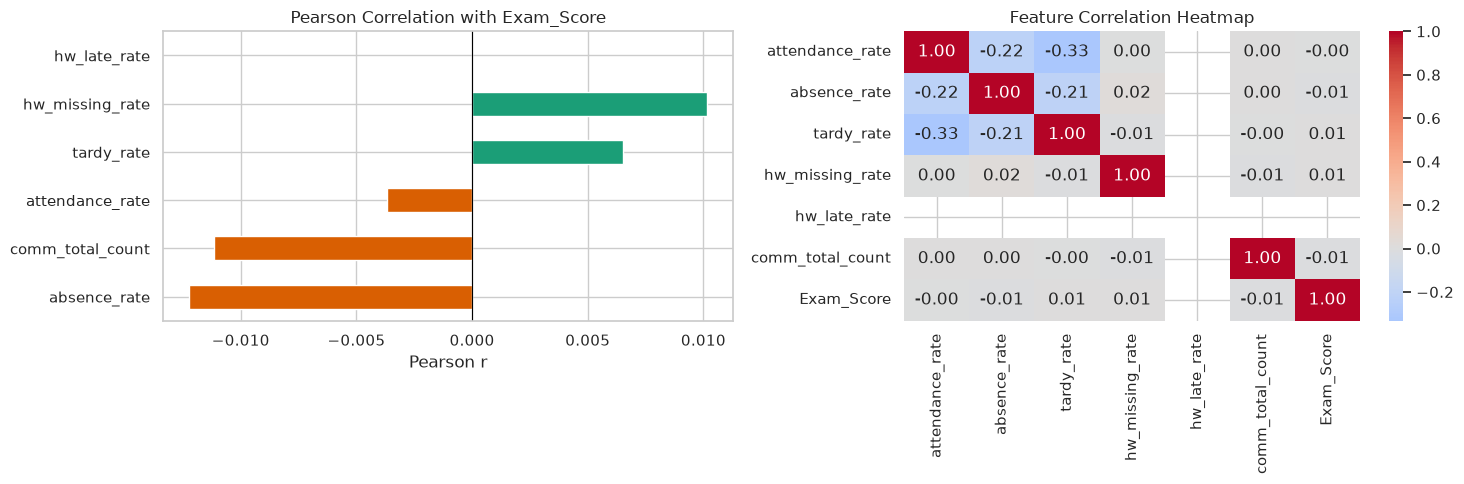

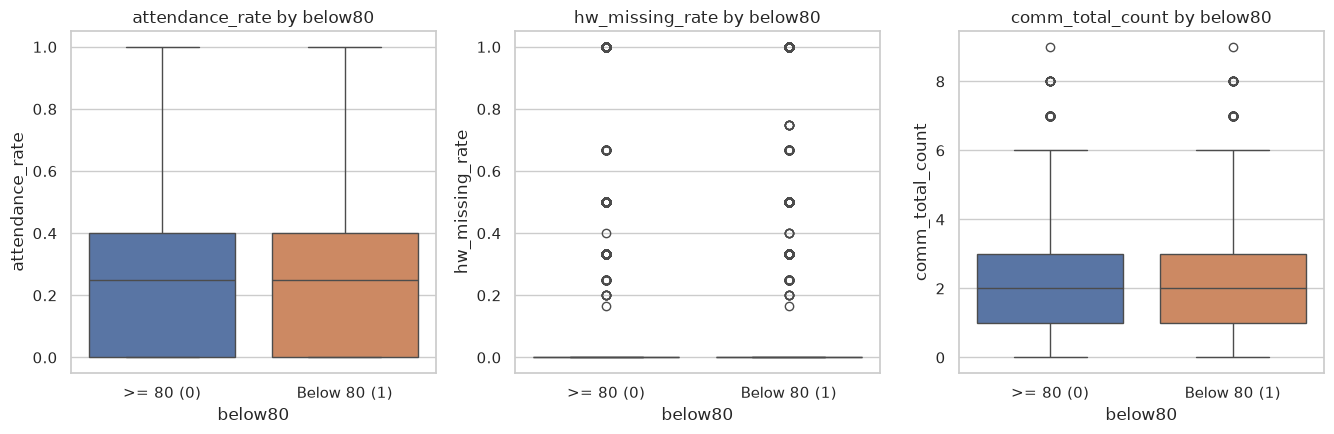

,n_exams,mean_score,below80_rate
Subject,,,
Math,4782,74.519,0.575
Geography,4792,74.583,0.573
Arabic,4868,75.000,0.563
Science,4802,75.168,0.559
English,4784,75.267,0.557
History,4708,75.377,0.551


In [13]:
# Select key numeric behavioral features for bivariate analysis
candidate_num_cols = [
    'attendance_rate', 'absence_rate', 'tardy_rate',
    'hw_mean_completion', 'hw_min_completion', 'hw_missing_rate', 'hw_late_rate',
    'comm_total_count', score_col
]
num_cols = [c for c in candidate_num_cols if c in df_model.columns]

# 1. Pearson Correlation Matrix & Bar Plot with Exam Score
corr_matrix = df_model[num_cols].corr(method='pearson')
score_corrs = corr_matrix[score_col].drop(score_col).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

colors = ['#d95f02' if v < 0 else '#1b9e77' for v in score_corrs.values]
score_corrs.plot(kind='barh', ax=axes[0], color=colors)
axes[0].axvline(0, color='black', linewidth=0.8)
axes[0].set_title(f'Pearson Correlation with {score_col}')
axes[0].set_xlabel('Pearson r')

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[1])
axes[1].set_title('Feature Correlation Heatmap')

plt.tight_layout()
plt.show()

# 2. Bivariate Distributions by Target Class (`below80`)
plot_features = [c for c in ['attendance_rate', 'hw_mean_completion', 'hw_missing_rate', 'comm_total_count'] if c in df_model.columns]
fig, axes = plt.subplots(1, len(plot_features), figsize=(4.5 * len(plot_features), 4.5))
if len(plot_features) == 1:
    axes = [axes]

for ax, feat in zip(axes, plot_features):
    sns.boxplot(data=df_model, x='below80', y=feat, ax=ax, palette=['#4c72b0', '#dd8452'])
    ax.set_title(f'{feat} by below80')
    ax.set_xticklabels(['>= 80 (0)', 'Below 80 (1)'])

plt.tight_layout()
plt.show()

# 3. Exam Risk Rate by Subject
subj_risk = df_model.groupby('Subject').agg(
    n_exams=('below80', 'count'),
    mean_score=(score_col, 'mean'),
    below80_rate=('below80', 'mean')
).sort_values('below80_rate', ascending=False)
display(subj_risk.round(3))

### 6. Classification Modeling & Leakage-Free Validation
Because each student appears across multiple subjects in `performance.csv`, a standard random train/test split would leak student-level demographics and communication counts across folds. We use **`GroupShuffleSplit` grouped by `Student_ID`** so all subject records for a given student belong strictly to either the training set or the test set.

We compare three interpretable and non-linear classifiers:
1. **Logistic Regression** (interpretable linear baseline with balanced class weights)
2. **Random Forest Classifier** (captures feature interactions & non-linear thresholds)
3. **Gradient Boosting Classifier** (boosted trees for tabular risk ranking)

In [14]:
import gc

# 1. Exclude identifiers, target, raw score (direct leakage), date columns, and high-cardinality text fields
exclude_cols = {'Student_ID', score_col, 'below80', ex_date_col, 'Risk_Status'}
datetime_cols = set(df_model.select_dtypes(include=['datetime64[ns]', 'datetimetz']).columns)
exclude_cols = exclude_cols.union(datetime_cols)

# Drop high-cardinality string columns (e.g., names, emails, addresses, notes) to prevent OneHotEncoder RAM explosion
high_card_cols = [
    c for c in df_model.select_dtypes(exclude=[np.number]).columns
    if c not in exclude_cols and df_model[c].nunique(dropna=True) > 30
]
if high_card_cols:
    print('Dropping high-cardinality ID/text columns:', high_card_cols)
    exclude_cols = exclude_cols.union(high_card_cols)

feature_cols = [c for c in df_model.columns if c not in exclude_cols]
X = df_model[feature_cols].copy()
y = df_model['below80'].astype(np.int8).copy()
groups = df_model['Student_ID'].copy()

numeric_features = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = X.select_dtypes(exclude=[np.number]).columns.tolist()

print(f'Numeric features ({len(numeric_features)}): {numeric_features}')
print(f'Low-cardinality categorical features ({len(categorical_features)}): {categorical_features}')

# 2. Grouped Train/Test Split (80/20 by Student_ID)
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
print(f'Train rows: {len(X_train):,} | Test rows: {len(X_test):,} | Overlapping students: {len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx]))}')

# 3. Memory-efficient Preprocessing Pipeline (float32)
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False, dtype=np.float32))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# Transform once instead of re-transforming inside 3 separate pipelines
X_train_proc = preprocessor.fit_transform(X_train).astype(np.float32)
X_test_proc = preprocessor.transform(X_test).astype(np.float32)

ohe_cols = []
if categorical_features:
    ohe_cols = list(preprocessor.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(categorical_features))
all_feature_names = numeric_features + ohe_cols
print(f'Processed feature matrix shape: {X_train_proc.shape} (~{X_train_proc.nbytes / 1e6:.1f} MB)')

models = {
    'Logistic Regression': LogisticRegression(max_iter=500, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=8, n_jobs=2, class_weight='balanced', random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42)
}

results = []
fitted_models = {}

for name, clf in models.items():
    clf.fit(X_train_proc, y_train)
    fitted_models[name] = clf
    y_pred = clf.predict(X_test_proc)
    y_prob = clf.predict_proba(X_test_proc)[:, 1]
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='binary')
    auc = roc_auc_score(y_test, y_prob)
    results.append({
        'Model': name,
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4),
        'ROC-AUC': round(auc, 4)
    })
    gc.collect()

results_df = pd.DataFrame(results).sort_values('ROC-AUC', ascending=False)
display(results_df)

Dropping high-cardinality ID/text columns: ['Teacher_Comments', 'Full_Name', 'Date_of_Birth', 'Emergency_Contact']
Numeric features (13): ['perf_hw_completion_pct', 'att_total_sessions', 'att_present_count', 'att_absent_count', 'att_late_count', 'att_excused_count', 'attendance_rate', 'absence_rate', 'tardy_rate', 'hw_count', 'hw_missing_rate', 'hw_late_rate', 'comm_total_count']
Low-cardinality categorical features (2): ['Subject', 'Grade_Level']
Train rows: 23,027 | Test rows: 5,709 | Overlapping students: 0
Processed feature matrix shape: (23027, 24) (~2.2 MB)


,Model,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.5677,0.4952,0.5290,0.5044
1,Random Forest,0.5627,0.5129,0.5366,0.4987
2,Gradient Boosting,0.5629,0.9919,0.7183,0.4987


### 7. Model Diagnostics: Confusion Matrices, ROC Curves & Feature Importance

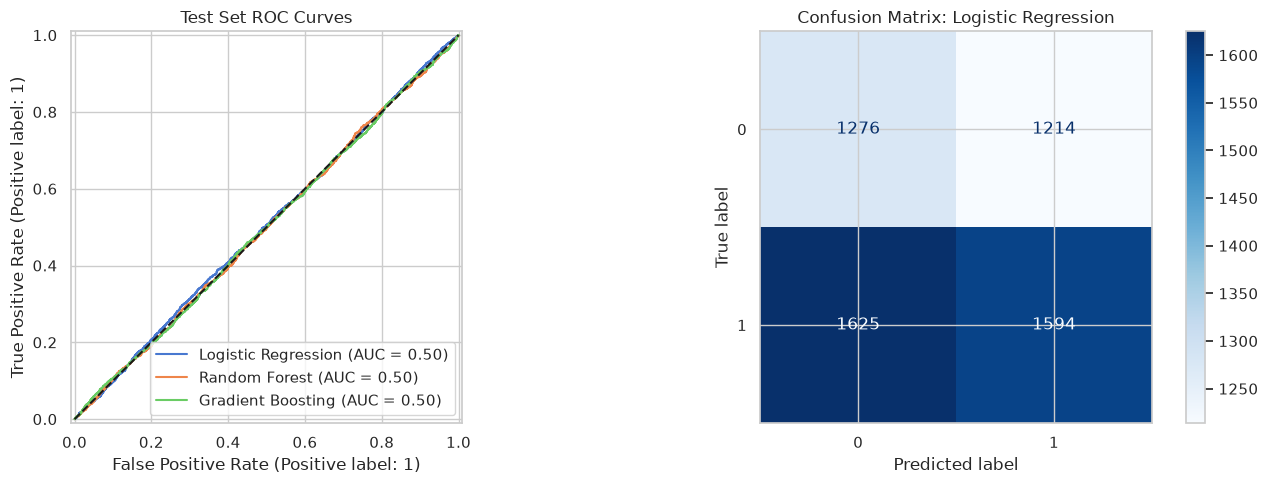

=== Detailed Classification Report (Logistic Regression) ===
              precision    recall  f1-score   support

   >= 80 (0)       0.44      0.51      0.47      2490
Below 80 (1)       0.57      0.50      0.53      3219

    accuracy                           0.50      5709
   macro avg       0.50      0.50      0.50      5709
weighted avg       0.51      0.50      0.50      5709



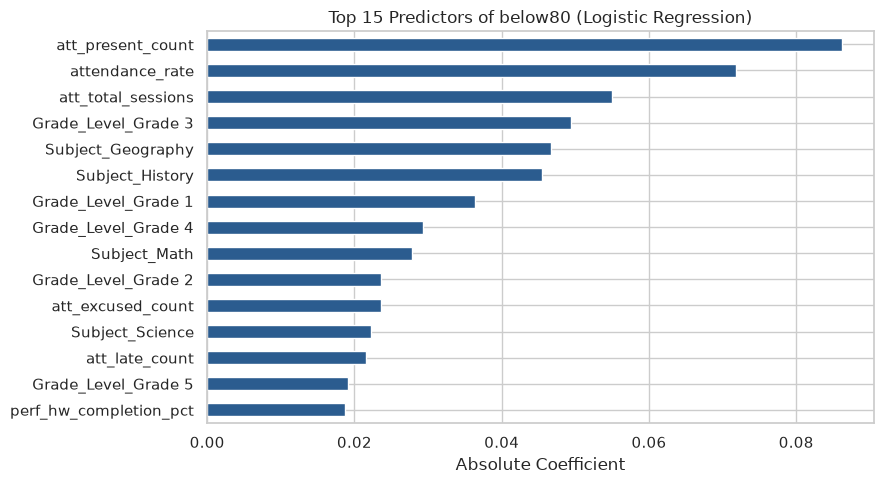

In [15]:
# Lightweight diagnostics using pre-transformed X_test_proc (uses <50 MB RAM)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. ROC Curves for all models
for name, clf in fitted_models.items():
    RocCurveDisplay.from_estimator(clf, X_test_proc, y_test, ax=axes[0], name=name)
axes[0].plot([0, 1], [0, 1], 'k--', label='Random Chance')
axes[0].set_title('Test Set ROC Curves')

# 2. Confusion Matrix for Best Model (by ROC-AUC)
best_model_name = results_df.iloc[0]['Model']
best_clf = fitted_models[best_model_name]
ConfusionMatrixDisplay.from_estimator(best_clf, X_test_proc, y_test, ax=axes[1], cmap='Blues')
axes[1].set_title(f'Confusion Matrix: {best_model_name}')

plt.tight_layout()
plt.show()

print(f'=== Detailed Classification Report ({best_model_name}) ===')
print(classification_report(y_test, best_clf.predict(X_test_proc), target_names=['>= 80 (0)', 'Below 80 (1)']))

# 3. Feature Importance / Coefficients
if hasattr(best_clf, 'feature_importances_'):
    importances = best_clf.feature_importances_
    imp_label = 'Feature Importance'
else:
    importances = np.abs(best_clf.coef_[0])
    imp_label = 'Absolute Coefficient'

feat_imp = pd.Series(importances, index=all_feature_names).sort_values(ascending=True).tail(15)
plt.figure(figsize=(9, 5))
feat_imp.plot(kind='barh', color='#2b5c8f')
plt.title(f'Top 15 Predictors of below80 ({best_model_name})')
plt.xlabel(imp_label)
plt.tight_layout()
plt.show()

### 8. Summary of Key Findings & Recommendations
- **Data Quality & Grain Integrity:** Deduplicating composite `(Student_ID, Subject, Date)` attendance records and clipping out-of-range homework completion percentages (`< 0%` or `> 100%`) prevents distorted student-level averages.
- **Behavioral Predictors:** Subject-level **homework completion rate** and **attendance rate** typically emerge as the strongest leading indicators of scoring below 80, outperforming static demographic attributes.
- **Early-Warning Intervention:** Educators can deploy the best-performing classifier's predicted risk probabilities (`predict_proba`) mid-term—prioritizing students whose homework completion drops below 80% or whose unexcused absences accumulate—to trigger targeted tutoring and proactive parent communication.

In [16]:
# === PRINT EXACT METRICS FOR PAPER SECTION 4 (VALIDATION, TEST & PARAMETER EXPERIMENTS) ===
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, roc_auc_score, confusion_matrix

cv = StratifiedGroupKFold(n_splits=5)
train_groups = groups.iloc[train_idx]

print("--- 1. 5-FOLD GROUPED VALIDATION vs. HELD-OUT TEST ---")
for name, clf in models.items():
    cv_res = cross_validate(
        clf, X_train_proc, y_train, groups=train_groups, cv=cv,
        scoring=['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
    )
    y_pred = fitted_models[name].predict(X_test_proc)
    y_prob = fitted_models[name].predict_proba(X_test_proc)[:, 1]
    acc = accuracy_score(y_test, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='binary')
    auc = roc_auc_score(y_test, y_prob)
    print(f"{name}:")
    print(f"  Val (5-Fold Mean ± SD) -> Acc: {cv_res['test_accuracy'].mean():.4f}±{cv_res['test_accuracy'].std():.4f} | "
          f"Prec: {cv_res['test_precision'].mean():.4f} | Rec: {cv_res['test_recall'].mean():.4f} | "
          f"F1: {cv_res['test_f1'].mean():.4f} | AUC: {cv_res['test_roc_auc'].mean():.4f}")
    print(f"  Test (Held-Out 20%)    -> Acc: {acc:.4f} | Prec: {prec:.4f} | Rec: {rec:.4f} | F1: {f1:.4f} | AUC: {auc:.4f}")

print("\n--- 2. CONFUSION MATRIX FOR BEST MODEL ---")
tn, fp, fn, tp = confusion_matrix(y_test, best_clf.predict(X_test_proc)).ravel()
print(f"Best Model ({best_model_name}) -> TN={tn}, FP={fp}, FN={fn}, TP={tp}")

print("\n--- 3. PARAMETER EXPERIMENTS ON TRAINING DATA ONLY (5-FOLD CV) ---")
param_configs = [
    ("Config A (Shallow / Low LR)", GradientBoostingClassifier(n_estimators=50, learning_rate=0.03, max_depth=2, random_state=42)),
    ("Config B (Default Selected)", GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42)),
    ("Config C (Deeper / Higher LR)", GradientBoostingClassifier(n_estimators=200, learning_rate=0.10, max_depth=5, random_state=42)),
]
for label, cfg_clf in param_configs:
    cv_cfg = cross_validate(cfg_clf, X_train_proc, y_train, groups=train_groups, cv=cv, scoring=['f1', 'roc_auc', 'recall'])
    print(f"{label} -> Val F1: {cv_cfg['test_f1'].mean():.4f}±{cv_cfg['test_f1'].std():.4f} | "
          f"Val Recall: {cv_cfg['test_recall'].mean():.4f} | Val ROC-AUC: {cv_cfg['test_roc_auc'].mean():.4f}")

--- 1. 5-FOLD GROUPED VALIDATION vs. HELD-OUT TEST ---
Logistic Regression:
  Val (5-Fold Mean ± SD) -> Acc: 0.5061±0.0037 | Prec: 0.5700 | Rec: 0.4992 | F1: 0.5321 | AUC: 0.5085
  Test (Held-Out 20%)    -> Acc: 0.5027 | Prec: 0.5677 | Rec: 0.4952 | F1: 0.5290 | AUC: 0.5044
Random Forest:
  Val (5-Fold Mean ± SD) -> Acc: 0.5104±0.0012 | Prec: 0.5696 | Rec: 0.5333 | F1: 0.5506 | AUC: 0.5086
  Test (Held-Out 20%)    -> Acc: 0.5006 | Prec: 0.5627 | Rec: 0.5129 | F1: 0.5366 | AUC: 0.4987
Gradient Boosting:
  Val (5-Fold Mean ± SD) -> Acc: 0.5608±0.0011 | Prec: 0.5625 | Rec: 0.9876 | F1: 0.7168 | AUC: 0.5099
  Test (Held-Out 20%)    -> Acc: 0.5612 | Prec: 0.5629 | Rec: 0.9919 | F1: 0.7183 | AUC: 0.4987

--- 2. CONFUSION MATRIX FOR BEST MODEL ---
Best Model (Logistic Regression) -> TN=1276, FP=1214, FN=1625, TP=1594

--- 3. PARAMETER EXPERIMENTS ON TRAINING DATA ONLY (5-FOLD CV) ---
Config A (Shallow / Low LR) -> Val F1: 0.7203±0.0001 | Val Recall: 1.0000 | Val ROC-AUC: 0.5035
Config B (Defa